<a href="https://colab.research.google.com/github/Shuvo-1/AI-Project/blob/main/IDS_vs_Bidirectional_BFS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving roadnet_ai_project.zip to roadnet_ai_project (1).zip


In [ ]:
!unzip -o roadnet_ai_project.zip -d /content/roadnet_ai_project

!ls -lh /content/roadnet_ai_project

Archive:  roadnet_ai_project.zip
  inflating: /content/roadnet_ai_project/IDS.cpp  
  inflating: /content/roadnet_ai_project/Bidirectional_BFS.cpp  
  inflating: /content/roadnet_ai_project/README.txt  
  inflating: /content/roadnet_ai_project/sample_comparison_results.csv  
total 32K
-rw-r--r-- 1 root root  11K Nov  9 06:41 Bidirectional_BFS.cpp
-rw-r--r-- 1 root root 9.3K Nov  9 06:41 IDS.cpp
-rw-r--r-- 1 root root 2.8K Nov  9 06:44 README.txt
-rw-r--r-- 1 root root  774 Nov  9 06:41 sample_comparison_results.csv


In [ ]:
!wget -q --show-progress -O /content/roadNet-PA.txt.gz https://snap.stanford.edu/data/roadNet-PA.txt.gz

/content/roadNet-PA 100%[===================>]   9.48M  1.84MB/s    in 6.0s    


In [ ]:
!gzip -t /content/roadNet-PA.txt.gz

!gunzip -kf /content/roadNet-PA.txt.gz

!ls -lh /content/roadNet-PA.txt

-rw-r--r-- 1 root root 44M Dec  3  2009 /content/roadNet-PA.txt


In [ ]:
%cd /content/roadnet_ai_project

!g++ -O2 -std=c++17 IDS.cpp -o IDS

!g++ -O2 -std=c++17 Bidirectional_BFS.cpp -o BiBFS

!ls -lh IDS BiBFS

/content/roadnet_ai_project
-rwxr-xr-x 1 root root 43K Nov 12 04:38 BiBFS
-rwxr-xr-x 1 root root 42K Nov 12 04:38 IDS


In [ ]:
!g++ -O2 -std=c++17 /content/roadnet_ai_project/IDS.cpp -o /content/roadnet_ai_project/IDS

In [ ]:
%cd /content/roadnet_ai_project

!g++ -O2 -std=c++17 -Wall -Wextra Bidirectional_BFS.cpp -o BiBFS

/content/roadnet_ai_project


In [ ]:
%cd /content/roadnet_ai_project

!g++ -O2 -std=c++17 IDS.cpp -o IDS

!g++ -O2 -std=c++17 Bidirectional_BFS.cpp -o BiBFS

/content/roadnet_ai_project


In [ ]:

%%writefile /content/roadnet_ai_project/IDS.cpp

#include <algorithm>
#include <chrono>
#include <cstdint>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <sstream>
#include <string>
#include <vector>
#include <utility>

using namespace std;
using Clock = chrono::steady_clock;

struct Graph {
    vector<vector<int>> adj;
    long long nodeCount = 0;
    long long edgeCount = 0;
    int maxNodeId = -1;
};

struct TestCase { int source; int target; };

// Keep these five pairs identical in the Bidirectional BFS program.
const vector<TestCase> TEST_CASES = {
    {0, 396},
    {0, 3063},
    {0, 3588},
    {0, 2732},
    {0, 38}
};

struct Stats {
    long long expandedNodes = 0;
    long long repeatedNodeExpansions = 0;
    long long edgeScans = 0;
    long long uniqueNodesEncountered = 0;
    size_t peakAuxBytes = 0;
};

template <typename T>
size_t vectorBytes(const vector<T>& v) {
    return v.capacity() * sizeof(T);
}

bool loadGraph(const string& filename, Graph& g) {
    ifstream in(filename);
    if (!in) {
        cerr << "Error: Cannot open dataset: " << filename << '\n';
        return false;
    }

    string line;
    while (getline(in, line)) {
        if (line.empty() || line[0] == '#') continue;
        int u, v;
        istringstream row(line);
        if (!(row >> u >> v) || u < 0 || v < 0) continue;

        g.maxNodeId = max(g.maxNodeId, max(u, v));
        if (static_cast<int>(g.adj.size()) <= g.maxNodeId)
            g.adj.resize(static_cast<size_t>(g.maxNodeId) + 1);
        if (u != v) {
            g.adj[u].push_back(v);
            g.adj[v].push_back(u);
        }
    }

    if (g.maxNodeId < 0) {
        cerr << "Error: Dataset contains no valid edges.\n";
        return false;
    }

    long long entries = 0;
    for (auto& nbrs : g.adj) {
        sort(nbrs.begin(), nbrs.end());
        nbrs.erase(unique(nbrs.begin(), nbrs.end()), nbrs.end());
        if (!nbrs.empty()) ++g.nodeCount;
        entries += static_cast<long long>(nbrs.size());
    }
    g.edgeCount = entries / 2;
    return true;
}

bool validNode(const Graph& g, int x) {
    return x >= 0 && x < static_cast<int>(g.adj.size()) && !g.adj[x].empty();
}

bool depthLimitedDFS(
    int u, int goal, int remainingDepth,
    const Graph& graph,
    vector<int>& bestRemaining,
    vector<int>& parent,
    vector<unsigned char>& seenEver,
    vector<unsigned char>& expandedBefore,
    uintptr_t baseStackAddress,
    Stats& stats
) {
    // Approximate actual recursive stack use from the distance between
    // this frame's local variable and a marker in main().
    volatile char stackMarker = 0;
    uintptr_t currentStackAddress = reinterpret_cast<uintptr_t>(&stackMarker);
    size_t stackBytes = (baseStackAddress > currentStackAddress)
        ? baseStackAddress - currentStackAddress
        : currentStackAddress - baseStackAddress;

    size_t currentBytes = vectorBytes(bestRemaining) + vectorBytes(parent)
        + vectorBytes(seenEver) + vectorBytes(expandedBefore) + stackBytes;
    stats.peakAuxBytes = max(stats.peakAuxBytes, currentBytes);

    if (bestRemaining[u] >= remainingDepth) return false;
    bestRemaining[u] = remainingDepth;

    if (!seenEver[u]) {
        seenEver[u] = 1;
        ++stats.uniqueNodesEncountered;
    }

    if (u == goal) return true;
    if (remainingDepth == 0) return false;

    if (expandedBefore[u]) ++stats.repeatedNodeExpansions;
    else expandedBefore[u] = 1;
    ++stats.expandedNodes;

    for (int v : graph.adj[u]) {
        ++stats.edgeScans;

        if (!seenEver[v]) {
            seenEver[v] = 1;
            ++stats.uniqueNodesEncountered;
        }

        if (bestRemaining[v] < remainingDepth - 1) {
            parent[v] = u;
            if (depthLimitedDFS(
                v, goal, remainingDepth - 1, graph,
                bestRemaining, parent, seenEver, expandedBefore,
                baseStackAddress, stats
            )) return true;
        }
    }
    return false;
}

void appendCSV(
    int testNo, int source, int target, bool found, int pathLength,
    double searchMs, double memoryMB, const Stats& s
) {
    const string filename = "comparison_results.csv";
    ifstream check(filename);
    bool headerNeeded = !check.good() || check.peek() == ifstream::traits_type::eof();
    check.close();

    ofstream out(filename, ios::app);
    if (!out) {
        cerr << "Warning: Could not write comparison_results.csv\n";
        return;
    }
    if (headerNeeded) {
        out << "Algorithm,Test_Case,Source,Destination,Path_Found,"
               "Shortest_Path_Length_Edges,Expanded_Nodes,Repeated_Node_Expansions,"
               "Edge_Scans,Unique_Nodes_Encountered,Search_Time_ms,"
               "Peak_Auxiliary_Memory_MB\n";
    }
    out << "IDS," << testNo << ',' << source << ',' << target << ','
        << (found ? "YES" : "NO") << ',' << pathLength << ','
        << s.expandedNodes << ',' << s.repeatedNodeExpansions << ','
        << s.edgeScans << ',' << s.uniqueNodesEncountered << ','
        << fixed << setprecision(3) << searchMs << ',' << memoryMB << '\n';
}

int main(int argc, char* argv[]) {
    string datasetFile = (argc >= 2) ? argv[1] : "/content/roadNet-PA.txt";

    Graph graph;
    if (!loadGraph(datasetFile, graph)) return 1;

    cout << "Dataset loaded. Running 5 IDS test cases.\n";

    for (size_t i = 0; i < TEST_CASES.size(); ++i) {
        const int source = TEST_CASES[i].source;
        const int target = TEST_CASES[i].target;
        const int testNo = static_cast<int>(i) + 1;

        Stats stats;
        bool found = false;
        vector<int> finalParent;
        vector<int> path;
        vector<unsigned char> seenEver(graph.adj.size(), 0);
        vector<unsigned char> expandedBefore(graph.adj.size(), 0);
        const int maxDepth = max(0, static_cast<int>(graph.nodeCount) - 1);

        cout << "\n----------------------------------------\n";
        cout << "Algorithm                 : Iterative Deepening Search (IDS)\n";
        cout << "Test Case                 : " << testNo << "/5\n";
        cout << "Source                    : " << source << '\n';
        cout << "Destination               : " << target << '\n';

        if (!validNode(graph, source) || !validNode(graph, target)) {
            cout << "Path Found                : No (invalid node)\n";
            cout << "Shortest Path Length      : N/A\n";
            cout << "Expanded Nodes            : 0\n";
            cout << "Repeated Node Expansions  : 0\n";
            cout << "Edge Scans                : 0\n";
            cout << "Unique Nodes Encountered  : 0\n";
            cout << "Search Time               : 0.000 ms\n";
            cout << "Peak Auxiliary Memory     : 0.000 MB\n";
            appendCSV(testNo, source, target, false, -1, 0.0, 0.0, stats);
            continue;
        }

        auto searchStart = Clock::now();
        for (int limit = 0; limit <= maxDepth; ++limit) {
            vector<int> bestRemaining(graph.adj.size(), -1);
            vector<int> parent(graph.adj.size(), -1);

            stats.peakAuxBytes = max(
                stats.peakAuxBytes,
                vectorBytes(bestRemaining) + vectorBytes(parent)
                    + vectorBytes(seenEver) + vectorBytes(expandedBefore)
            );

            volatile char baseStackMarker = 0;
            uintptr_t baseStackAddress = reinterpret_cast<uintptr_t>(&baseStackMarker);

            if (depthLimitedDFS(
                source, target, limit, graph,
                bestRemaining, parent, seenEver, expandedBefore,
                baseStackAddress, stats
            )) {
                found = true;
                finalParent = move(parent);
                break;
            }
        }
        auto searchEnd = Clock::now();
        double searchMs = chrono::duration<double, milli>(searchEnd - searchStart).count();

        if (found) {
            for (int x = target; x != -1; x = finalParent[x]) {
                path.push_back(x);
                if (x == source) break;
            }
            if (path.empty() || path.back() != source) {
                found = false;
                path.clear();
            } else {
                reverse(path.begin(), path.end());
            }
        }

        int pathLength = found ? static_cast<int>(path.size()) - 1 : -1;
        double memoryMB = stats.peakAuxBytes / (1024.0 * 1024.0);

        cout << "Path Found                : " << (found ? "Yes" : "No") << '\n';
        cout << "Shortest Path Length      : ";
        if (found) cout << pathLength << " edges\n"; else cout << "N/A\n";
        cout << "Expanded Nodes            : " << stats.expandedNodes << '\n';
        cout << "Repeated Node Expansions  : " << stats.repeatedNodeExpansions << '\n';
        cout << "Edge Scans                : " << stats.edgeScans << '\n';
        cout << "Unique Nodes Encountered  : " << stats.uniqueNodesEncountered << '\n';
        cout << "Search Time               : " << fixed << setprecision(3) << searchMs << " ms\n";
        cout << "Peak Auxiliary Memory     : " << fixed << setprecision(3) << memoryMB << " MB\n";

        appendCSV(testNo, source, target, found, pathLength, searchMs, memoryMB, stats);
    }

    cout << "\nAll 5 IDS test cases completed.\n";
    cout << "Results saved to comparison_results.csv\n";
    return 0;
}



Overwriting /content/roadnet_ai_project/IDS.cpp


In [ ]:

%%writefile /content/roadnet_ai_project/Bidirectional_BFS.cpp

#include <algorithm>
#include <chrono>
#include <fstream>
#include <iomanip>
#include <iostream>
#include <sstream>
#include <string>
#include <vector>
#include <limits>

using namespace std;
using Clock = chrono::steady_clock;

struct Graph {
    vector<vector<int>> adj;
    long long nodeCount = 0;
    long long edgeCount = 0;
    int maxNodeId = -1;
};

struct TestCase { int source; int target; };

// EXACTLY the same five pairs as in IDS_5_TestCases_Updated.cpp.
const vector<TestCase> TEST_CASES = {
    {0, 396},
    {0, 3063},
    {0, 3588},
    {0, 2732},
    {0, 38}
};

struct Stats {
    long long expandedNodes = 0;
    long long repeatedNodeExpansions = 0;
    long long edgeScans = 0;
    long long uniqueNodesEncountered = 0;
    size_t peakAuxBytes = 0;
};

template <typename T>
size_t vectorBytes(const vector<T>& v) {
    return v.capacity() * sizeof(T);
}

bool loadGraph(const string& filename, Graph& g) {
    ifstream in(filename);
    if (!in) {
        cerr << "Error: Cannot open dataset: " << filename << '\n';
        return false;
    }

    string line;
    while (getline(in, line)) {
        if (line.empty() || line[0] == '#') continue;
        int u, v;
        istringstream row(line);
        if (!(row >> u >> v) || u < 0 || v < 0) continue;

        g.maxNodeId = max(g.maxNodeId, max(u, v));
        if (static_cast<int>(g.adj.size()) <= g.maxNodeId)
            g.adj.resize(static_cast<size_t>(g.maxNodeId) + 1);
        if (u != v) {
            g.adj[u].push_back(v);
            g.adj[v].push_back(u);
        }
    }

    if (g.maxNodeId < 0) {
        cerr << "Error: Dataset contains no valid edges.\n";
        return false;
    }

    long long entries = 0;
    for (auto& nbrs : g.adj) {
        sort(nbrs.begin(), nbrs.end());
        nbrs.erase(unique(nbrs.begin(), nbrs.end()), nbrs.end());
        if (!nbrs.empty()) ++g.nodeCount;
        entries += static_cast<long long>(nbrs.size());
    }
    g.edgeCount = entries / 2;
    return true;
}

bool validNode(const Graph& g, int x) {
    return x >= 0 && x < static_cast<int>(g.adj.size()) && !g.adj[x].empty();
}

void updateBest(
    int candidate, int fNode, int bNode,
    int& bestDistance, int& bestF, int& bestB
) {
    if (candidate < bestDistance) {
        bestDistance = candidate;
        bestF = fNode;
        bestB = bNode;
    }
}

size_t currentAuxBytes(
    const vector<int>& distF, const vector<int>& distB,
    const vector<int>& parentF, const vector<int>& parentB,
    const vector<unsigned char>& seenEver,
    const vector<unsigned char>& expandedBefore,
    const vector<int>& frontierF, const vector<int>& frontierB,
    const vector<int>& next
) {
    return vectorBytes(distF) + vectorBytes(distB)
        + vectorBytes(parentF) + vectorBytes(parentB)
        + vectorBytes(seenEver) + vectorBytes(expandedBefore)
        + vectorBytes(frontierF) + vectorBytes(frontierB)
        + vectorBytes(next);
}

void appendCSV(
    int testNo, int source, int target, bool found, int pathLength,
    double searchMs, double memoryMB, const Stats& s
) {
    const string filename = "comparison_results.csv";
    ifstream check(filename);
    bool headerNeeded = !check.good() || check.peek() == ifstream::traits_type::eof();
    check.close();

    ofstream out(filename, ios::app);
    if (!out) {
        cerr << "Warning: Could not write comparison_results.csv\n";
        return;
    }
    if (headerNeeded) {
        out << "Algorithm,Test_Case,Source,Destination,Path_Found,"
               "Shortest_Path_Length_Edges,Expanded_Nodes,Repeated_Node_Expansions,"
               "Edge_Scans,Unique_Nodes_Encountered,Search_Time_ms,"
               "Peak_Auxiliary_Memory_MB\n";
    }
    out << "Bidirectional BFS," << testNo << ',' << source << ',' << target << ','
        << (found ? "YES" : "NO") << ',' << pathLength << ','
        << s.expandedNodes << ',' << s.repeatedNodeExpansions << ','
        << s.edgeScans << ',' << s.uniqueNodesEncountered << ','
        << fixed << setprecision(3) << searchMs << ',' << memoryMB << '\n';
}

int main(int argc, char* argv[]) {
    string datasetFile = (argc >= 2) ? argv[1] : "/content/roadNet-PA.txt";

    Graph graph;
    if (!loadGraph(datasetFile, graph)) return 1;

    cout << "Dataset loaded. Running 5 Bidirectional BFS test cases.\n";
    const int n = static_cast<int>(graph.adj.size());
    const int INF = numeric_limits<int>::max();

    for (size_t i = 0; i < TEST_CASES.size(); ++i) {
        const int source = TEST_CASES[i].source;
        const int target = TEST_CASES[i].target;
        const int testNo = static_cast<int>(i) + 1;

        Stats stats;
        bool found = false;
        int bestDistance = INF, bestF = -1, bestB = -1;
        vector<int> path;

        cout << "\n----------------------------------------\n";
        cout << "Algorithm                 : Bidirectional BFS\n";
        cout << "Test Case                 : " << testNo << "/5\n";
        cout << "Source                    : " << source << '\n';
        cout << "Destination               : " << target << '\n';

        if (!validNode(graph, source) || !validNode(graph, target)) {
            cout << "Path Found                : No (invalid node)\n";
            cout << "Shortest Path Length      : N/A\n";
            cout << "Expanded Nodes            : 0\n";
            cout << "Repeated Node Expansions  : 0\n";
            cout << "Edge Scans                : 0\n";
            cout << "Unique Nodes Encountered  : 0\n";
            cout << "Search Time               : 0.000 ms\n";
            cout << "Peak Auxiliary Memory     : 0.000 MB\n";
            appendCSV(testNo, source, target, false, -1, 0.0, 0.0, stats);
            continue;
        }

        auto searchStart = Clock::now();

        vector<int> distF(n, -1), distB(n, -1);
        vector<int> parentF(n, -1), parentB(n, -1);
        vector<unsigned char> seenEver(n, 0), expandedBefore(n, 0);
        vector<int> frontierF{source}, frontierB{target};

        distF[source] = 0;
        distB[target] = 0;

        auto markSeen = [&](int node) {
            if (!seenEver[node]) {
                seenEver[node] = 1;
                ++stats.uniqueNodesEncountered;
            }
        };
        auto markExpanded = [&](int node) {
            if (expandedBefore[node]) ++stats.repeatedNodeExpansions;
            else expandedBefore[node] = 1;
            ++stats.expandedNodes;
        };

        markSeen(source);
        markSeen(target);

        vector<int> emptyNext;
        stats.peakAuxBytes = currentAuxBytes(
            distF, distB, parentF, parentB, seenEver, expandedBefore,
            frontierF, frontierB, emptyNext
        );

        int depthF = 0, depthB = 0;

        if (source == target) {
            bestDistance = 0;
            bestF = source;
            bestB = target;
        } else {
            while (!frontierF.empty() && !frontierB.empty()) {
                // Each frontier contains one complete, unexpanded BFS level.
                if (bestDistance != INF && depthF + depthB >= bestDistance)
                    break;

                // Expand one complete level from the smaller frontier.
                if (frontierF.size() <= frontierB.size()) {
                    vector<int> next;
                    for (int u : frontierF) {
                        markExpanded(u);
                        if (distB[u] != -1)
                            updateBest(distF[u] + distB[u], u, u,
                                       bestDistance, bestF, bestB);

                        for (int v : graph.adj[u]) {
                            ++stats.edgeScans;
                            if (distB[v] != -1)
                                updateBest(distF[u] + 1 + distB[v], u, v,
                                           bestDistance, bestF, bestB);

                            if (distF[v] == -1) {
                                distF[v] = distF[u] + 1;
                                parentF[v] = u;
                                next.push_back(v);
                                markSeen(v);
                                if (distB[v] != -1)
                                    updateBest(distF[v] + distB[v], v, v,
                                               bestDistance, bestF, bestB);
                            }
                            stats.peakAuxBytes = max(
                                stats.peakAuxBytes,
                                currentAuxBytes(distF, distB, parentF, parentB,
                                    seenEver, expandedBefore, frontierF, frontierB, next)
                            );
                        }
                    }
                    stats.peakAuxBytes = max(
                        stats.peakAuxBytes,
                        currentAuxBytes(distF, distB, parentF, parentB,
                            seenEver, expandedBefore, frontierF, frontierB, next)
                    );
                    frontierF.swap(next);
                    ++depthF;
                } else {
                    vector<int> next;
                    for (int u : frontierB) {
                        markExpanded(u);
                        if (distF[u] != -1)
                            updateBest(distF[u] + distB[u], u, u,
                                       bestDistance, bestF, bestB);

                        for (int v : graph.adj[u]) {
                            ++stats.edgeScans;
                            if (distF[v] != -1)
                                updateBest(distF[v] + 1 + distB[u], v, u,
                                           bestDistance, bestF, bestB);

                            if (distB[v] == -1) {
                                distB[v] = distB[u] + 1;
                                parentB[v] = u;
                                next.push_back(v);
                                markSeen(v);
                                if (distF[v] != -1)
                                    updateBest(distF[v] + distB[v], v, v,
                                               bestDistance, bestF, bestB);
                            }
                            stats.peakAuxBytes = max(
                                stats.peakAuxBytes,
                                currentAuxBytes(distF, distB, parentF, parentB,
                                    seenEver, expandedBefore, frontierF, frontierB, next)
                            );
                        }
                    }
                    stats.peakAuxBytes = max(
                        stats.peakAuxBytes,
                        currentAuxBytes(distF, distB, parentF, parentB,
                            seenEver, expandedBefore, frontierF, frontierB, next)
                    );
                    frontierB.swap(next);
                    ++depthB;
                }
            }
        }

        auto searchEnd = Clock::now();
        double searchMs = chrono::duration<double, milli>(searchEnd - searchStart).count();
        found = (bestDistance != INF);

        if (found) {
            vector<int> left;
            for (int x = bestF; x != -1; x = parentF[x]) left.push_back(x);
            reverse(left.begin(), left.end());
            path = left;

            int rightStart = (bestF == bestB) ? parentB[bestB] : bestB;
            for (int x = rightStart; x != -1; x = parentB[x]) path.push_back(x);

            if (path.empty() || path.front() != source || path.back() != target ||
                static_cast<int>(path.size()) - 1 != bestDistance) {
                found = false;
                path.clear();
            }
        }

        int pathLength = found ? bestDistance : -1;
        double memoryMB = stats.peakAuxBytes / (1024.0 * 1024.0);

        cout << "Path Found                : " << (found ? "Yes" : "No") << '\n';
        cout << "Shortest Path Length      : ";
        if (found) cout << pathLength << " edges\n"; else cout << "N/A\n";
        cout << "Expanded Nodes            : " << stats.expandedNodes << '\n';
        cout << "Repeated Node Expansions  : " << stats.repeatedNodeExpansions << '\n';
        cout << "Edge Scans                : " << stats.edgeScans << '\n';
        cout << "Unique Nodes Encountered  : " << stats.uniqueNodesEncountered << '\n';
        cout << "Search Time               : " << fixed << setprecision(3) << searchMs << " ms\n";
        cout << "Peak Auxiliary Memory     : " << fixed << setprecision(3) << memoryMB << " MB\n";

        appendCSV(testNo, source, target, found, pathLength, searchMs, memoryMB, stats);
    }

    cout << "\nAll 5 Bidirectional BFS test cases completed.\n";
    cout << "Results saved to comparison_results.csv\n";
    return 0;
}


Overwriting /content/roadnet_ai_project/Bidirectional_BFS.cpp


In [ ]:
%cd /content/roadnet_ai_project

!g++ -O2 -std=c++17 -Wall -Wextra IDS.cpp -o IDS

!g++ -O2 -std=c++17 -Wall -Wextra Bidirectional_BFS.cpp -o BiBFS

/content/roadnet_ai_project


In [ ]:
!rm -f comparison_results.csv

In [ ]:
!./IDS /content/roadNet-PA.txt

Dataset loaded. Running 5 IDS test cases.

----------------------------------------
Algorithm                 : Iterative Deepening Search (IDS)
Test Case                 : 1/5
Source                    : 0
Destination               : 396
Path Found                : Yes
Shortest Path Length      : 10 edges
Expanded Nodes            : 1449
Repeated Node Expansions  : 1165
Edge Scans                : 4490
Unique Nodes Encountered  : 364
Search Time               : 5.225 ms
Peak Auxiliary Memory     : 10.405 MB

----------------------------------------
Algorithm                 : Iterative Deepening Search (IDS)
Test Case                 : 2/5
Source                    : 0
Destination               : 3063
Path Found                : Yes
Shortest Path Length      : 13 edges
Expanded Nodes            : 4168
Repeated Node Expansions  : 3676
Edge Scans                : 12681
Unique Nodes Encountered  : 590
Search Time               : 3.001 ms
Peak Auxiliary Memory     : 10.406 MB

-----------

In [ ]:
!./BiBFS /content/roadNet-PA.txt

Dataset loaded. Running 5 Bidirectional BFS test cases.

----------------------------------------
Algorithm                 : Bidirectional BFS
Test Case                 : 1/5
Source                    : 0
Destination               : 396
Path Found                : Yes
Shortest Path Length      : 10 edges
Expanded Nodes            : 81
Repeated Node Expansions  : 0
Edge Scans                : 252
Unique Nodes Encountered  : 134
Search Time               : 5.795 ms
Peak Auxiliary Memory     : 18.727 MB

----------------------------------------
Algorithm                 : Bidirectional BFS
Test Case                 : 2/5
Source                    : 0
Destination               : 3063
Path Found                : Yes
Shortest Path Length      : 13 edges
Expanded Nodes            : 203
Repeated Node Expansions  : 0
Edge Scans                : 626
Unique Nodes Encountered  : 297
Search Time               : 1.917 ms
Peak Auxiliary Memory     : 18.728 MB

---------------------------------------

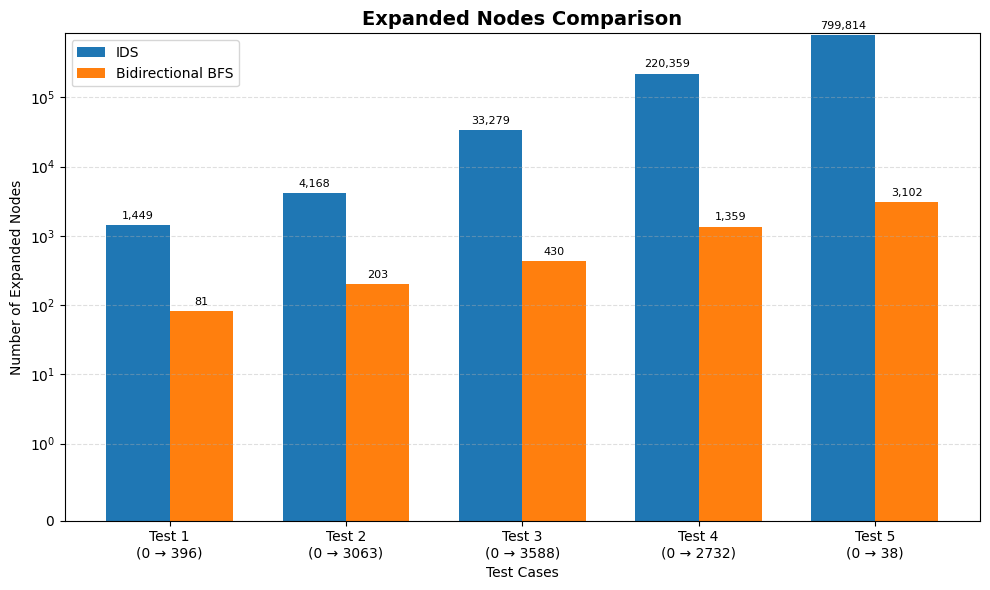

Saved: /content/roadnet_ai_project/graphs/expanded_nodes.png


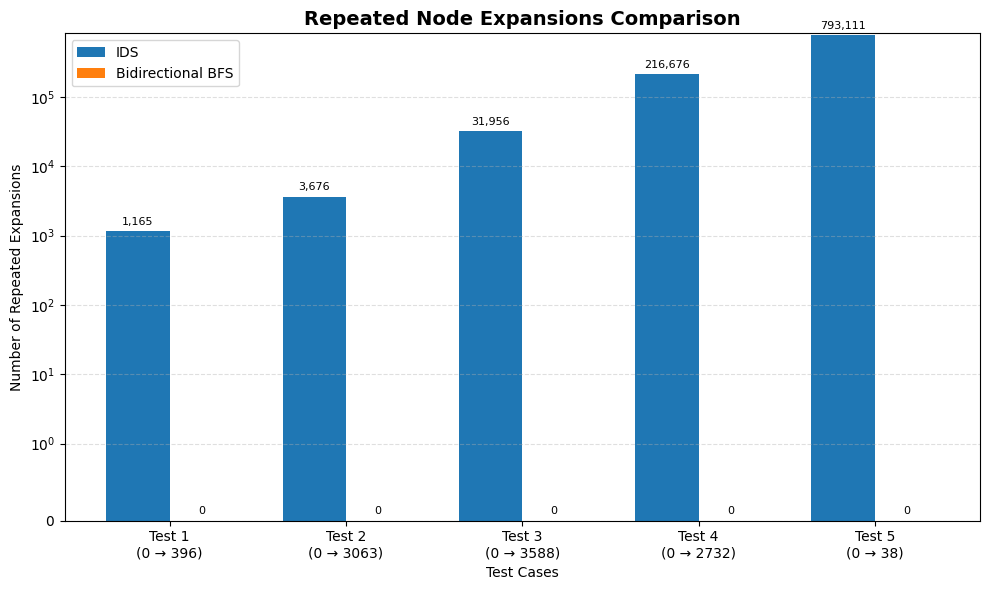

Saved: /content/roadnet_ai_project/graphs/repeated_node_expansions.png


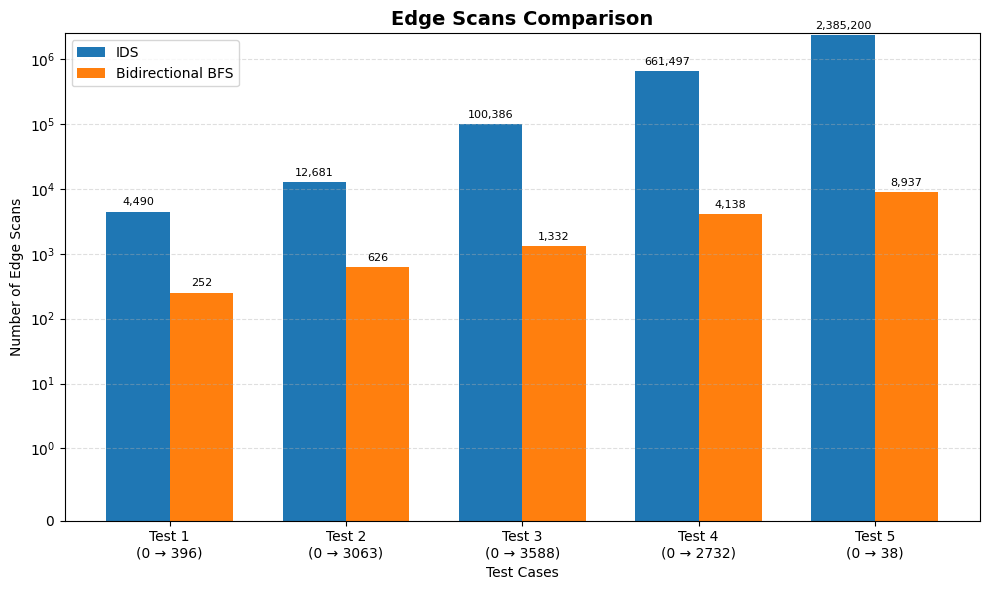

Saved: /content/roadnet_ai_project/graphs/edge_scans.png


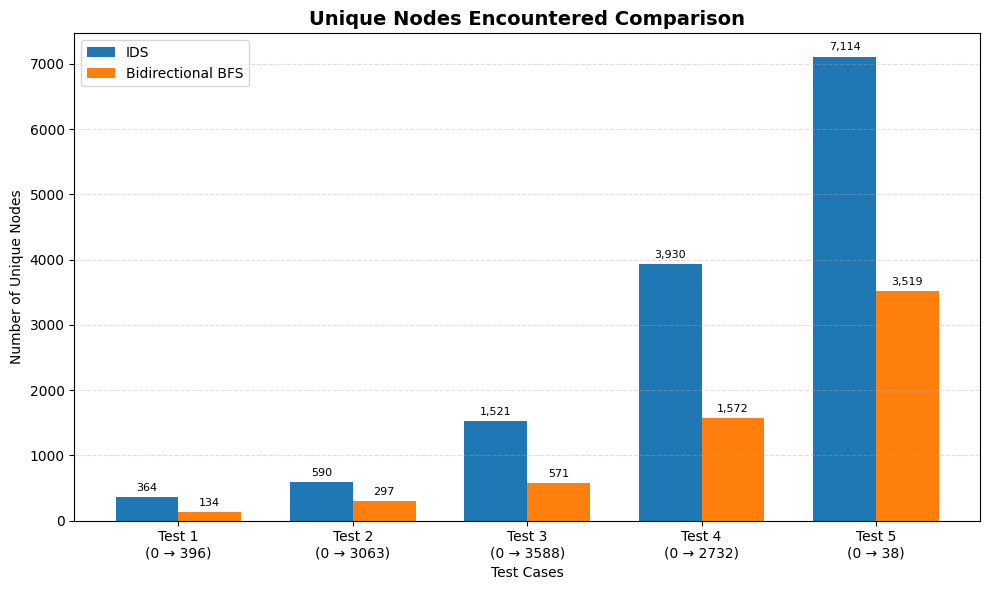

Saved: /content/roadnet_ai_project/graphs/unique_nodes.png


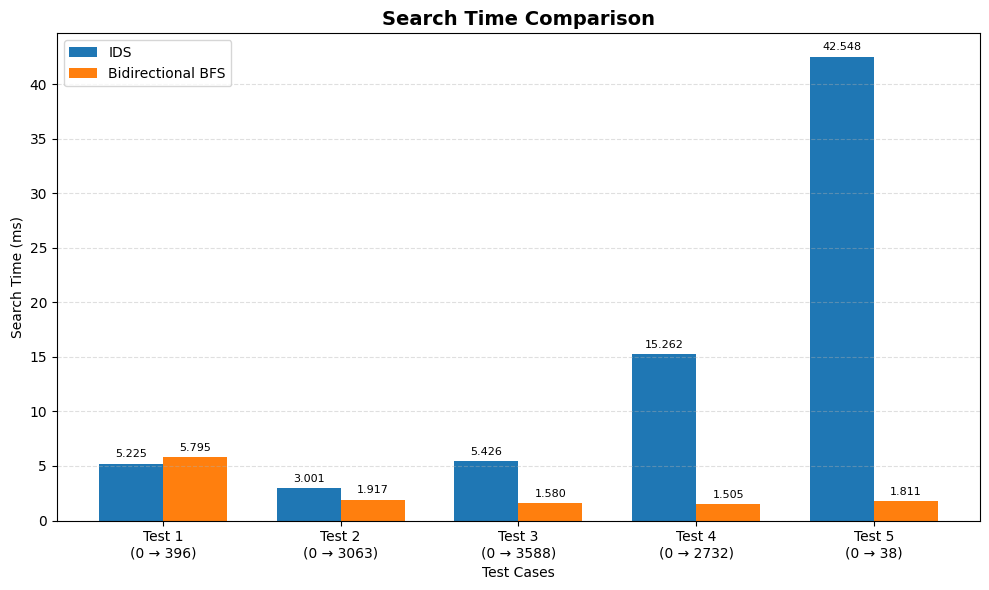

Saved: /content/roadnet_ai_project/graphs/search_time.png


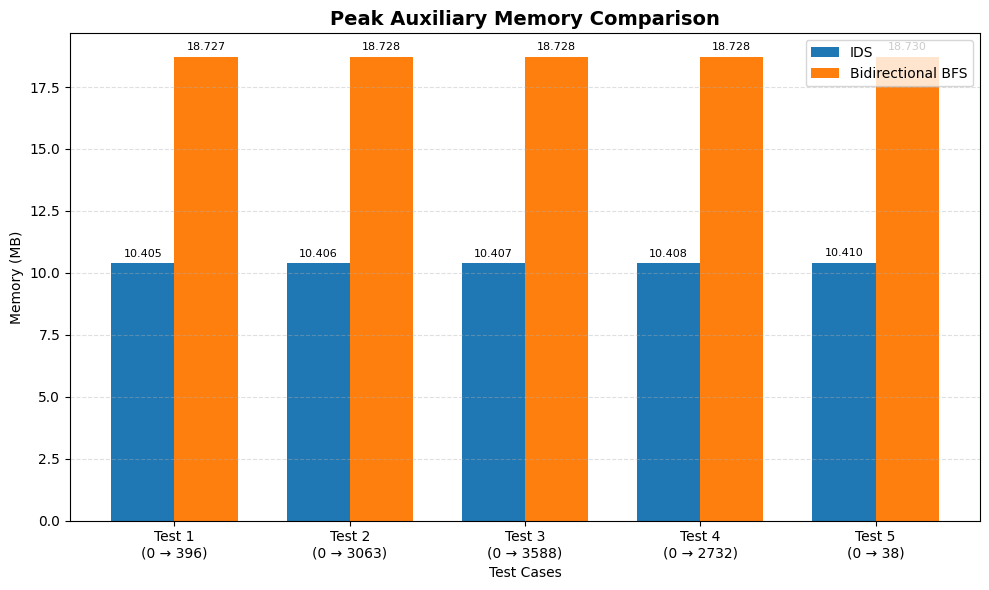

Saved: /content/roadnet_ai_project/graphs/peak_auxiliary_memory.png


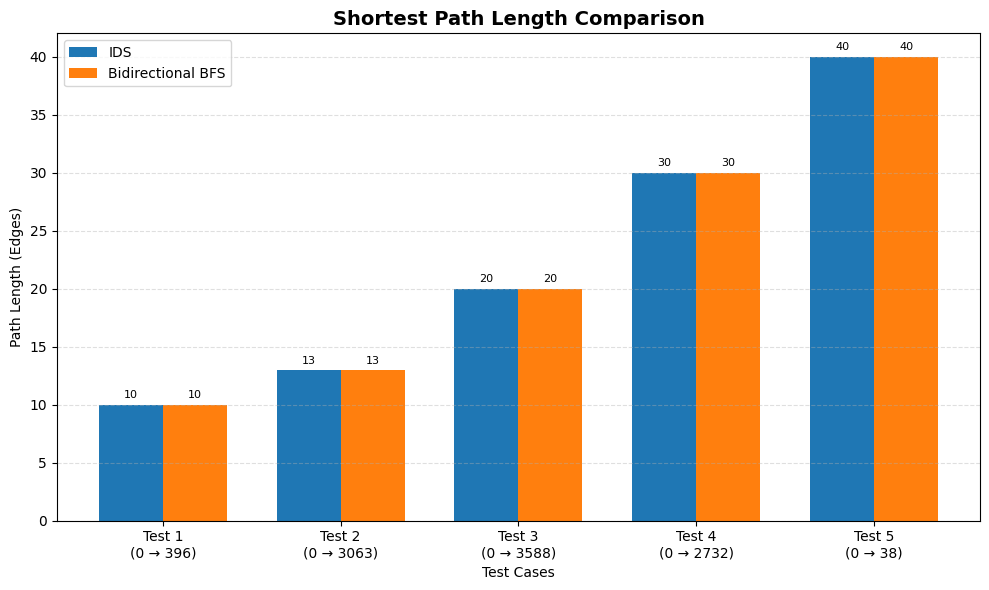

Saved: /content/roadnet_ai_project/graphs/shortest_path_length.png

All individual graphs generated successfully!


In [ ]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# CSV file location
CSV_FILE = "/content/roadnet_ai_project/comparison_results.csv"

# Folder to save all graphs
OUTPUT_DIR = "/content/roadnet_ai_project/graphs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Read CSV file
df = pd.read_csv(CSV_FILE)

# Clean algorithm names
df["Algorithm"] = df["Algorithm"].str.strip()

# Convert test case and numeric columns
numeric_columns = [
    "Test_Case",
    "Source",
    "Destination",
    "Shortest_Path_Length_Edges",
    "Expanded_Nodes",
    "Repeated_Node_Expansions",
    "Edge_Scans",
    "Unique_Nodes_Encountered",
    "Search_Time_ms",
    "Peak_Auxiliary_Memory_MB"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# If CSV contains multiple runs, calculate average for each test case
metrics = [
    "Shortest_Path_Length_Edges",
    "Expanded_Nodes",
    "Repeated_Node_Expansions",
    "Edge_Scans",
    "Unique_Nodes_Encountered",
    "Search_Time_ms",
    "Peak_Auxiliary_Memory_MB"
]

df_avg = (
    df.groupby(["Algorithm", "Test_Case"], as_index=False)[metrics]
    .mean()
)

algorithms = ["IDS", "Bidirectional BFS"]

# Test case labels with source and destination
case_info = (
    df[["Test_Case", "Source", "Destination"]]
    .drop_duplicates("Test_Case")
    .sort_values("Test_Case")
)

test_cases = case_info["Test_Case"].tolist()

labels = [
    f"Test {int(row.Test_Case)}\n({int(row.Source)} → {int(row.Destination)})"
    for row in case_info.itertuples()
]

# Individual graph titles and labels
graph_details = {
    "Expanded_Nodes": (
        "Expanded Nodes Comparison",
        "Number of Expanded Nodes",
        "expanded_nodes.png"
    ),
    "Repeated_Node_Expansions": (
        "Repeated Node Expansions Comparison",
        "Number of Repeated Expansions",
        "repeated_node_expansions.png"
    ),
    "Edge_Scans": (
        "Edge Scans Comparison",
        "Number of Edge Scans",
        "edge_scans.png"
    ),
    "Unique_Nodes_Encountered": (
        "Unique Nodes Encountered Comparison",
        "Number of Unique Nodes",
        "unique_nodes.png"
    ),
    "Search_Time_ms": (
        "Search Time Comparison",
        "Search Time (ms)",
        "search_time.png"
    ),
    "Peak_Auxiliary_Memory_MB": (
        "Peak Auxiliary Memory Comparison",
        "Memory (MB)",
        "peak_auxiliary_memory.png"
    ),
    "Shortest_Path_Length_Edges": (
        "Shortest Path Length Comparison",
        "Path Length (Edges)",
        "shortest_path_length.png"
    )
}

# Parameters where a symmetric log scale helps show both algorithms
log_metrics = [
    "Expanded_Nodes",
    "Repeated_Node_Expansions",
    "Edge_Scans"
]

# Generate individual graphs
for metric, details in graph_details.items():

    title, ylabel, filename = details

    x = np.arange(len(test_cases))
    width = 0.36

    fig, ax = plt.subplots(figsize=(10, 6))

    for i, algorithm in enumerate(algorithms):

        algorithm_data = (
            df_avg[df_avg["Algorithm"] == algorithm]
            .set_index("Test_Case")
        )

        values = algorithm_data[metric].reindex(test_cases)

        offset = (i - 0.5) * width

        bars = ax.bar(
            x + offset,
            values,
            width,
            label=algorithm
        )

        # Add values above bars
        if metric in [
            "Expanded_Nodes",
            "Repeated_Node_Expansions",
            "Edge_Scans",
            "Unique_Nodes_Encountered",
            "Shortest_Path_Length_Edges"
        ]:
            value_labels = [
                f"{v:,.0f}" if pd.notna(v) else ""
                for v in values
            ]
        else:
            value_labels = [
                f"{v:.3f}" if pd.notna(v) else ""
                for v in values
            ]

        ax.bar_label(
            bars,
            labels=value_labels,
            padding=3,
            fontsize=8
        )

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel("Test Cases")
    ax.set_ylabel(ylabel)

    ax.set_xticks(x)
    ax.set_xticklabels(labels)

    ax.legend()
    ax.grid(axis="y", linestyle="--", alpha=0.4)

    # Log-like scale for large differences and zero values
    if metric in log_metrics:
        ax.set_yscale("symlog", linthresh=1)

    plt.tight_layout()

    # Save graph
    graph_path = os.path.join(OUTPUT_DIR, filename)
    plt.savefig(graph_path, dpi=300, bbox_inches="tight")

    plt.show()
    plt.close()

    print("Saved:", graph_path)

print("\nAll individual graphs generated successfully!")


In [ ]:
from google.colab import files
files.download('/content/roadnet_ai_project/comparison_results.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>